In [3]:
import pandas as pd, numpy as np, os
p="C:/Users/hp/Desktop/Practice/Data_Analysis/Dataset_task2/dirty_cafe_sales.csv"
df=pd.read_csv(p)
df.shape, df.head(10).to_dict('records'), df.dtypes.astype(str).to_dict(), df.isna().sum().to_dict(), df.duplicated().sum()

((10000, 8),
 [{'Transaction ID': 'TXN_1961373',
   'Item': 'Coffee',
   'Quantity': '2',
   'Price Per Unit': '2.0',
   'Total Spent': '4.0',
   'Payment Method': 'Credit Card',
   'Location': 'Takeaway',
   'Transaction Date': '2023-09-08'},
  {'Transaction ID': 'TXN_4977031',
   'Item': 'Cake',
   'Quantity': '4',
   'Price Per Unit': '3.0',
   'Total Spent': '12.0',
   'Payment Method': 'Cash',
   'Location': 'In-store',
   'Transaction Date': '2023-05-16'},
  {'Transaction ID': 'TXN_4271903',
   'Item': 'Cookie',
   'Quantity': '4',
   'Price Per Unit': '1.0',
   'Total Spent': 'ERROR',
   'Payment Method': 'Credit Card',
   'Location': 'In-store',
   'Transaction Date': '2023-07-19'},
  {'Transaction ID': 'TXN_7034554',
   'Item': 'Salad',
   'Quantity': '2',
   'Price Per Unit': '5.0',
   'Total Spent': '10.0',
   'Payment Method': 'UNKNOWN',
   'Location': 'UNKNOWN',
   'Transaction Date': '2023-04-27'},
  {'Transaction ID': 'TXN_3160411',
   'Item': 'Coffee',
   'Quantity': '2

In [4]:
for c in df.columns:
    print('\n',c, 'unique', df[c].nunique(dropna=True))
    if df[c].nunique(dropna=True)<30: print(df[c].value_counts(dropna=False).to_string())
for c in ['Quantity','Price Per Unit','Total Spent']:
    s=pd.to_numeric(df[c], errors='coerce')
    print('\n',c,'coerce null',s.isna().sum(),'describe',s.describe().to_dict(),'bad',df.loc[s.isna(),c].value_counts().head(10).to_dict())
dt=pd.to_datetime(df['Transaction Date'],errors='coerce')
print('date invalid',dt.isna().sum(), 'minmax',dt.min(),dt.max())
for c in ['Quantity','Price Per Unit','Total Spent']:
    s=pd.to_numeric(df[c],errors='coerce')
    q1,q3=s.quantile([.25,.75]); iqr=q3-q1
    print(c, 'minmax',s.min(),s.max(),'IQR fences',q1-1.5*iqr,q3+1.5*iqr,'outliers',((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum())


 Transaction ID unique 10000

 Item unique 10
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292

 Quantity unique 7
Quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
NaN         138

 Price Per Unit unique 8
Price Per Unit
3.0        2429
4.0        2331
2.0        1227
5.0        1204
1.0        1143
1.5        1133
ERROR       190
NaN         179
UNKNOWN     164

 Total Spent unique 19
Total Spent
6.0        979
12.0       939
3.0        930
4.0        923
20.0       746
15.0       734
8.0        677
10.0       524
2.0        497
9.0        479
5.0        468
16.0       444
25.0       259
7.5        237
1.0        232
4.5        225
1.5        205
NaN        173
UNKNOWN    165
ERROR      164

 Payment Method unique 5
Payment Method
NaN               2579
Digital Wallet    2

In [5]:
num=pd.DataFrame({c:pd.to_numeric(df[c],errors='coerce') for c in ['Quantity','Price Per Unit','Total Spent']})
valid=num.dropna()
mismatch=((num['Total Spent'].notna())&(num['Quantity'].notna())&(num['Price Per Unit'].notna()) & ((num['Total Spent']-num['Quantity']*num['Price Per Unit']).abs()>0.01))
mismatch.sum(), df.loc[mismatch,['Quantity','Price Per Unit','Total Spent']].head(10)

(np.int64(0),
 Empty DataFrame
 Columns: [Quantity, Price Per Unit, Total Spent]
 Index: [])

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [9]:
df = pd.read_csv("C:/Users/hp/Desktop/Practice/Data_Analysis/Dataset_task2/dirty_cafe_sales.csv")
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [10]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 10000
Number of Columns: 8


In [11]:
print(df.columns)

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date'],
      dtype='str')


In [14]:
df.describe(include='all')

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


In [15]:
df.isnull().sum()

Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64

In [16]:
for col in df.select_dtypes(include='object').columns:
    print("\nColumn:", col)
    print(df[col].value_counts(dropna=False))


Column: Transaction ID
Transaction ID
TXN_1961373    1
TXN_4977031    1
TXN_4271903    1
TXN_7034554    1
TXN_3160411    1
              ..
TXN_7672686    1
TXN_9659401    1
TXN_5255387    1
TXN_7695629    1
TXN_6170729    1
Name: count, Length: 10000, dtype: int64

Column: Item
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292
Name: count, dtype: int64

Column: Quantity
Quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
NaN         138
Name: count, dtype: int64

Column: Price Per Unit
Price Per Unit
3.0        2429
4.0        2331
2.0        1227
5.0        1204
1.0        1143
1.5        1133
ERROR       190
NaN         179
UNKNOWN     164
Name: count, dtype: int64

Column: Total Spent
Total Spent
6.0        979
12.0       939
3.0        930
4.0        923
20.0       746
15.

In [17]:
missing_values = df.isnull().sum()
print("Missing Values Per Column:")
print(missing_values)

Missing Values Per Column:
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64


In [18]:
duplicate_count = df.duplicated().sum()
print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


In [19]:
print("Current Data Types:")
print(df.dtypes)

Current Data Types:
Transaction ID      str
Item                str
Quantity            str
Price Per Unit      str
Total Spent         str
Payment Method      str
Location            str
Transaction Date    str
dtype: object


In [20]:
invalid_values = ['ERROR', 'UNKNOWN']
for col in df.columns:
    count = df[col].isin(invalid_values).sum()
    if count > 0:
        print(col, ":", count, "invalid values")

Item : 636 invalid values
Quantity : 341 invalid values
Price Per Unit : 354 invalid values
Total Spent : 329 invalid values
Payment Method : 599 invalid values
Location : 696 invalid values
Transaction Date : 301 invalid values


In [21]:
numeric_columns = [
    'Quantity',
    'Price Per Unit',
    'Total Spent'
]
for col in numeric_columns:
    temp = pd.to_numeric(df[col], errors='coerce')
    print("\nColumn:", col)
    print("Minimum:", temp.min())
    print("Maximum:", temp.max())
    print("Mean:", temp.mean())
    print("Median:", temp.median())


Column: Quantity
Minimum: 1.0
Maximum: 5.0
Mean: 3.028463396702027
Median: 3.0

Column: Price Per Unit
Minimum: 1.0
Maximum: 5.0
Mean: 2.949984155487483
Median: 3.0

Column: Total Spent
Minimum: 1.0
Maximum: 25.0
Mean: 8.924352495262161
Median: 8.0


In [22]:
df.replace(['ERROR', 'UNKNOWN', ''], np.nan, inplace=True)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,NaN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02


In [23]:
numeric_columns = ['Quantity', 'Price Per Unit']
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    median_value = df[col].median()
    df[col].fillna(median_value, inplace=True)
    print(col, "missing values filled with:", median_value)

Quantity missing values filled with: 3.0
Price Per Unit missing values filled with: 3.0


In [24]:
df['Total Spent'] = pd.to_numeric(
    df['Total Spent'],
    errors='coerce'
)
missing_total = df['Total Spent'].isnull()
df.loc[missing_total, 'Total Spent'] = (
    df.loc[missing_total, 'Quantity'] *
    df.loc[missing_total, 'Price Per Unit']
)
print("Missing Total Spent after cleaning:",
      df['Total Spent'].isnull().sum())

Missing Total Spent after cleaning: 40


In [25]:
categorical_columns = [
    'Item',
    'Payment Method',
    'Location'
]
for col in categorical_columns:
    mode_value = df[col].mode()[0]
    df[col].fillna(mode_value, inplace=True)
    print(col, "filled with:", mode_value)

Item filled with: Juice
Payment Method filled with: Digital Wallet
Location filled with: Takeaway


In [26]:
df['Transaction Date'] = pd.to_datetime(
    df['Transaction Date'],
    errors='coerce',
    format='mixed'
)
before_date_cleaning = len(df)
df.dropna(subset=['Transaction Date'], inplace=True)
removed_date_rows = before_date_cleaning - len(df)
print("Rows removed due to invalid/missing dates:",
      removed_date_rows)

Rows removed due to invalid/missing dates: 460


In [27]:
duplicate_count = df.duplicated().sum()
print("Duplicate Rows Before Removal:",
      duplicate_count)

Duplicate Rows Before Removal: 0


In [28]:
df.drop_duplicates(inplace=True)
print("Duplicate Rows After Removal:",
      df.duplicated().sum())

Duplicate Rows After Removal: 0


In [30]:
df.reset_index(drop=True, inplace=True)

In [31]:
text_columns = [
    'Transaction ID',
    'Item',
    'Payment Method',
    'Location'
]
for col in text_columns:
    df[col] = df[col].astype('string').str.strip()

In [32]:
df['Item'] = df['Item'].str.title()

df['Payment Method'] = df['Payment Method'].str.title()

df['Location'] = df['Location'].str.title()

In [33]:
df['Transaction Date'] = pd.to_datetime(
    df['Transaction Date'],
    errors='coerce'
)
df['Transaction Date'].head()

0   2023-09-08
1   2023-05-16
2   2023-07-19
3   2023-04-27
4   2023-06-11
Name: Transaction Date, dtype: datetime64[us]

In [34]:
numeric_columns = [
    'Quantity',
    'Price Per Unit',
    'Total Spent'
]
outlier_summary = []
for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]
    outlier_summary.append({
        'Column': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers)
    })
outlier_df = pd.DataFrame(outlier_summary)
print(outlier_df)

           Column  Lower Bound  Upper Bound  Outlier Count
0        Quantity         -1.0          7.0              0
1  Price Per Unit         -1.0          7.0              0
2     Total Spent         -8.0         24.0            259


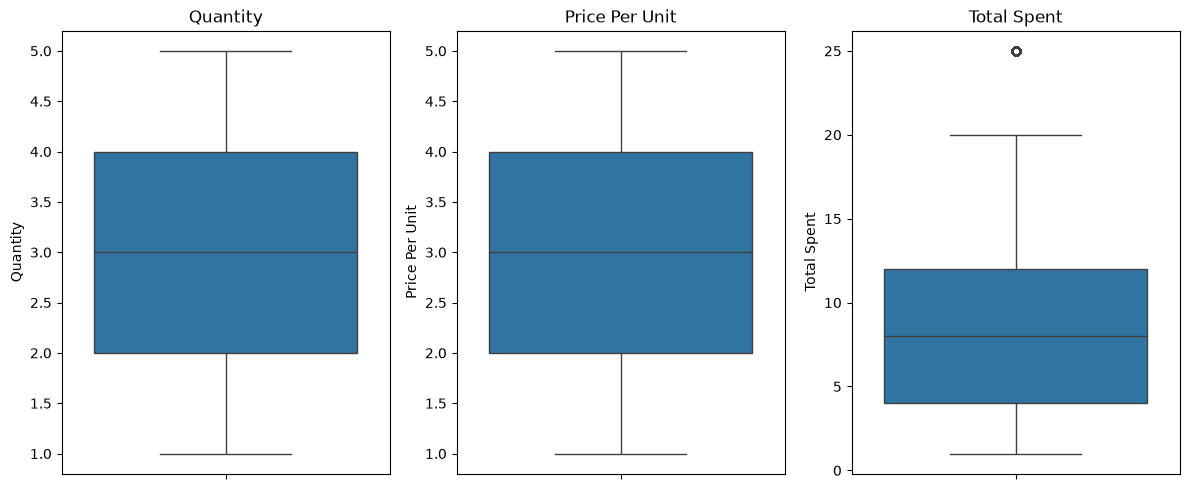

In [35]:
plt.figure(figsize=(12, 5))
for i, col in enumerate(numeric_columns, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [36]:
print("Outliers identified:")
print(outlier_df)

Outliers identified:
           Column  Lower Bound  Upper Bound  Outlier Count
0        Quantity         -1.0          7.0              0
1  Price Per Unit         -1.0          7.0              0
2     Total Spent         -8.0         24.0            259


In [38]:
df['Transaction ID'] = df['Transaction ID'].astype('string')
df['Quantity'] = df['Quantity'].astype('float64')
df['Price Per Unit'] = df['Price Per Unit'].astype('float64')
df['Total Spent'] = df['Total Spent'].astype('float64')
df['Transaction Date'] = pd.to_datetime(
    df['Transaction Date']
)
for col in ['Item', 'Payment Method', 'Location']:
    df[col] = df[col].astype('category')

In [39]:
print(df.dtypes)

Transaction ID              string
Item                      category
Quantity                   float64
Price Per Unit             float64
Total Spent                float64
Payment Method            category
Location                  category
Transaction Date    datetime64[us]
dtype: object


In [40]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nFinal Dataset:")
display(df.head())

Missing Values:
Transaction ID         0
Item                 927
Quantity             454
Price Per Unit       506
Total Spent           39
Payment Method      3015
Location            3779
Transaction Date       0
dtype: int64

Duplicate Rows:
0

Dataset Shape:
(9540, 8)

Data Types:
Transaction ID              string
Item                      category
Quantity                   float64
Price Per Unit             float64
Total Spent                float64
Payment Method            category
Location                  category
Transaction Date    datetime64[us]
dtype: object

Final Dataset:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-Store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-Store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,<NA>,<NA>,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-Store,2023-06-11


In [41]:
calculated_total = df['Quantity'] * df['Price Per Unit']

incorrect_total = (
    df['Total Spent'] - calculated_total
).abs() > 0.01

print("Incorrect Total Spent Records:",
      incorrect_total.sum())

Incorrect Total Spent Records: 0


In [42]:
df_original = df.copy()

In [43]:
expected_dtypes = {
    'Transaction ID': 'string',
    'Item': 'category',
    'Quantity': 'int64',
    'Price Per Unit': 'float64',
    'Total Spent': 'float64',
    'Payment Method': 'category',
    'Location': 'category',
    'Transaction Date': 'datetime64[ns]'
}
before_nulls = df_original.replace(
    ['ERROR', 'UNKNOWN', ''], np.nan
).isnull().sum().sum()

before_duplicates = df_original.duplicated().sum()
before_rows = len(df_original)
before_dtype_accuracy = sum(
    str(df_original[col].dtype) == dtype
    for col, dtype in expected_dtypes.items()
)

after_nulls = df.isnull().sum().sum()
after_duplicates = df.duplicated().sum()
after_rows = len(df)
after_dtype_accuracy = sum(
    str(df[col].dtype) == dtype
    for col, dtype in expected_dtypes.items()
)

comparison = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Missing Values',
        'Duplicate Rows',
        'Correct Data Types'
    ],

    'Before Cleaning': [
        before_rows,
        before_nulls,
        before_duplicates,
        f'{before_dtype_accuracy}/8'
    ],

    'After Cleaning': [
        after_rows,
        after_nulls,
        after_duplicates,
        f'{after_dtype_accuracy}/8'
    ]
})
display(comparison)

,Metric,Before Cleaning,After Cleaning
0,Total Rows,9540,9540
1,Missing Values,8720,8720
2,Duplicate Rows,0,0
3,Correct Data Types,6/8,6/8


In [44]:
df.to_csv(
    'cleaned_cafe_sales.csv',
    index=False
)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
